In [1]:
import torch
import pandas as pd
import numpy as np

import random
import ast

from sklearn.preprocessing import StandardScaler
scaleStandard = StandardScaler()
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

In [2]:
df_relaxase_raw = pd.read_csv("../data/processed/relaxase_oriT_dataset.csv")

df_relax = df_relaxase_raw.dropna(subset=['oriT_nic_seq'])

df_relax = df_relax.drop(columns=['oriTDB_accession', 'oriTDB_id', 'nic site', 'host', 'sDBM_sim_gap', 'relaxase_family'])

df_relax = df_relax.drop_duplicates(subset=["sDBM", "oriT_nic_seq"], keep='first')

df_relax = df_relax[["sDBM_pos", "sDBM", "oriT_nic_seq", "relaxase_sequence"]]

df_relax.rename(columns={"sDBM_pos": "sDBM_pos", "sDBM": "sDBM", "oriT_nic_seq": "ori_nic_seq", "relaxase_sequence": "amino_acid_seq"}, inplace=True)

df_relax

,sDBM_pos,sDBM,ori_nic_seq,amino_acid_seq
0,"(4, 12)",HVPMRSIKK,TATCCTGCC,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...
2,"(4, 12)",HLTAKTGSR,AAGTGCGCC,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...
3,"(4, 12)",VEKDYRVKR,TATCCTGCA,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...
5,"(2, 10)",IAKRENGKR,AAGTGCGCC,MTIAKRENGKRSLIAMASYRSGEKLYSELYEKTNLYNHRTVKPEAF...
6,"(2, 10)",SISSIKGDA,CGGGTGTGG,MLSISSIKGDAGYYSHEDNYYASGSLDSRWMGEGAEKLGLKGEVAS...
...,...,...,...,...
1336,"(9, 17)",VELAKYLQD,TGTCCTGCC,MRNVKKSSFVELAKYLQDPQSKQERVGVIKVTNCHQENILDAARYD...
1371,"(4, 12)",AAALQHCYR,AAGTGCGCC,MGTVAAALQHCYRDRETPNADQERTPDNDHLAARSTDEAMGKLRER...
1376,"(1, 9)",VLTRQDIGR,ATTGTCTAT,MVLTRQDIGRAASYYEDGADDYYAKDGDASEWQGKGAEELGLSGEV...
1379,"(24, 32)",TIVGNLNKN,TCGATTGGT,MYSNSRLSGQTLGKSQPELSFDAMTIVGNLNKNNAQKLSEFMSVEP...


In [3]:
df_rep = pd.read_csv("../data/processed/unique_rep_oriR_dataset.csv")

df_rep.rename(columns={"sDBM_pos": "sDBM_pos", "sDBM": "sDBM", "ori_seq": "ori_nic_seq", "rep_amino_acid_seq": "amino_acid_seq"}, inplace=True)

df_rep

,sDBM_pos,sDBM,ori_nic_seq,amino_acid_seq
0,"(63, 71)",GAHFEKRRG,TAGTATTAC,MARQVICWCFTLNNPLSPLSLHDSMKYLVYQTEQGEAGNIHFQGYI...
1,"(63, 71)",GAHLEKRKG,TATTATTAC,MARYVVCWMFTINNPSSLPVMRDEIKYMVYQVERGQEGTRHVQGYV...
2,"(73, 81)",KPHLEKQRA,GACTGCTAC,MAAIKGQWWCFTVFFLTATAPDLVPLFENTHVSYACWQEEESPTTK...
3,"(70, 78)",RAHWEKARG,TAGTATTAC,MSASRWTFTLHYSDATERGKFLATLKEEDVHYAVVGDETAPNTGRK...
4,"(74, 82)",RAHFECAKG,CAGTATTAC,MAPRGNAAKRWTFTINNWTLADYDKVLEFTTKFEPVFLICGKERGE...
...,...,...,...,...
224,"(64, 72)",QAHIEESNH,TAGTAATAC,MKVYLITAPRSTPKKALKIMIEKNDCKKWIIGWEKGKNGYEHFQIR...
225,"(64, 72)",AAHIEEAQQ,CATTTGTAC,MKKYIMTVPRSVPKKALKIMIDVNDCKKWIIGKERGKNGYEHWQIR...
226,"(63, 71)",GWHVEDCVS,CAGTATTAC,MKYVATIPRDGIKESQLVRLLQTLDLHEAYLGREIGDGGYRHYQCA...
227,"(72, 80)",RAHWEPRRG,TAGTATTAC,MEHRKGRGTFSKDWVFTLNNYNEEDKELIEGIDCQYVIYGKEVGEN...


In [8]:
import random
import pandas as pd
from Bio.Align import PairwiseAligner


def add_wrong_9mers(
    df: pd.DataFrame,
    *,
    nucleotide_col=None,
    protein_col=None,
    distant_fraction=0.10,
    seed=None,
) -> pd.DataFrame:
    """Replace each row's 9-mer with one from a dissimilar protein row."""
    result = df.copy()
    cols = list(df.columns)

    nucleotide_col = nucleotide_col or cols[2]
    protein_col = protein_col or cols[3]

    rng = random.Random(seed)
    proteins = df[protein_col].fillna("").astype(str).tolist()
    original_9mers = df[nucleotide_col].tolist()
    n = len(df)

    if n < 2:
        raise ValueError("At least two rows are needed to select a donor.")

    aligner = PairwiseAligner()
    aligner.mode = "global"
    aligner.match_score = 2
    aligner.mismatch_score = -1
    aligner.open_gap_score = -5
    aligner.extend_gap_score = -0.5

    self_scores = [aligner.score(p, p) for p in proteins]
    similarities = [[0.0] * n for _ in range(n)]

    for i in range(n):
        for j in range(i + 1, n):
            score = aligner.score(proteins[i], proteins[j])
            denom = self_scores[i] + self_scores[j]
            similarity = 2 * score / denom if denom else 0.0
            similarities[i][j] = similarities[j][i] = similarity

    bases = "ACGT"
    replacements = []

    for i in range(n):
        candidates = [j for j in range(n) if j != i]
        candidates.sort(key=lambda j: similarities[i][j])

        k = max(1, round(len(candidates) * distant_fraction))
        donor = rng.choice(candidates[:k])
        selected_9mer = original_9mers[donor]

        if selected_9mer == original_9mers[i]:
            if not isinstance(selected_9mer, str) or len(selected_9mer) != 9:
                raise ValueError(
                    f"Row {df.index[i]!r} has a matching 9-mer that is not a "
                    "9-character string."
                )

            # Mutate one of the first seven bases to a different base.
            position = rng.randrange(7)
            current_base = selected_9mer[position].upper()
            alternatives = [base for base in bases if base != current_base]
            mutated_base = rng.choice(alternatives)

            selected_9mer = (
                selected_9mer[:position]
                + mutated_base
                + selected_9mer[position + 1:]
            )

        replacements.append(selected_9mer)

    result[nucleotide_col] = replacements
    return result

In [9]:
negative_rep = add_wrong_9mers(df_rep, seed=42)

negative_rep


,sDBM_pos,sDBM,ori_nic_seq,amino_acid_seq
0,"(63, 71)",GAHFEKRRG,TACTACTAC,MARQVICWCFTLNNPLSPLSLHDSMKYLVYQTEQGEAGNIHFQGYI...
1,"(63, 71)",GAHLEKRKG,TAATGGTAC,MARYVVCWMFTINNPSSLPVMRDEIKYMVYQVERGQEGTRHVQGYV...
2,"(73, 81)",KPHLEKQRA,AAATGTTAC,MAAIKGQWWCFTVFFLTATAPDLVPLFENTHVSYACWQEEESPTTK...
3,"(70, 78)",RAHWEKARG,TATTTCTAC,MSASRWTFTLHYSDATERGKFLATLKEEDVHYAVVGDETAPNTGRK...
4,"(74, 82)",RAHFECAKG,TTATACTAC,MAPRGNAAKRWTFTINNWTLADYDKVLEFTTKFEPVFLICGKERGE...
...,...,...,...,...
224,"(64, 72)",QAHIEESNH,TAACACTAC,MKVYLITAPRSTPKKALKIMIEKNDCKKWIIGWEKGKNGYEHFQIR...
225,"(64, 72)",AAHIEEAQQ,TACTTCTAC,MKKYIMTVPRSVPKKALKIMIDVNDCKKWIIGKERGKNGYEHWQIR...
226,"(63, 71)",GWHVEDCVS,TAGTATTAC,MKYVATIPRDGIKESQLVRLLQTLDLHEAYLGREIGDGGYRHYQCA...
227,"(72, 80)",RAHWEPRRG,TAATACGAC,MEHRKGRGTFSKDWVFTLNNYNEEDKELIEGIDCQYVIYGKEVGEN...


In [10]:
negative_relax = add_wrong_9mers(df_relax, seed=42)

negative_relax

,sDBM_pos,sDBM,ori_nic_seq,amino_acid_seq
0,"(4, 12)",HVPMRSIKK,TATCCCGCG,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...
2,"(4, 12)",HLTAKTGSR,AGTGTGTGG,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...
3,"(4, 12)",VEKDYRVKR,TACCCGCGC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...
5,"(2, 10)",IAKRENGKR,ATACTAGCT,MTIAKRENGKRSLIAMASYRSGEKLYSELYEKTNLYNHRTVKPEAF...
6,"(2, 10)",SISSIKGDA,TATACTGGC,MLSISSIKGDAGYYSHEDNYYASGSLDSRWMGEGAEKLGLKGEVAS...
...,...,...,...,...
1336,"(9, 17)",VELAKYLQD,TATCCCGCG,MRNVKKSSFVELAKYLQDPQSKQERVGVIKVTNCHQENILDAARYD...
1371,"(4, 12)",AAALQHCYR,GGGGTGTGA,MGTVAAALQHCYRDRETPNADQERTPDNDHLAARSTDEAMGKLRER...
1376,"(1, 9)",VLTRQDIGR,ATACTGGCT,MVLTRQDIGRAASYYEDGADDYYAKDGDASEWQGKGAEELGLSGEV...
1379,"(24, 32)",TIVGNLNKN,GGGGTGTGA,MYSNSRLSGQTLGKSQPELSFDAMTIVGNLNKNNAQKLSEFMSVEP...


In [11]:
same_9mer = df_relax.iloc[:, 2].eq(negative_relax.iloc[:, 2])

print(f"{same_9mer.sum()} rows kept the original 9-mer")
print(f"{same_9mer.mean():.1%} of rows kept the original 9-mer")

# Show matching rows
matching_rows = df_relax.loc[same_9mer]

0 rows kept the original 9-mer
0.0% of rows kept the original 9-mer


In [9]:
from esm.models.esmc import EsmcForMaskedLM, EsmcTokenizer
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# ESMC-300M Pretrained model
model = EsmcForMaskedLM.from_pretrained(
    "biohub/ESMC-300M",
    device=device,
).eval()

tokenizer = EsmcTokenizer()

ESMC: Transformer Engine is not installed; falling back to pure-PyTorch LayerNorm+Linear / LayerNorm+MLP. Outputs will differ numerically - measured on the unnormalized residual stream (before the final LayerNorm), ~O(10) max-diff in fp32 and ~O(100) in bf16; after the final LayerNorm these shrink to a few ULP and perplexity stays within rounding noise. Install with `pip install transformer-engine[pytorch]` to enable fused fp32-reduction LayerNorm.
ESMC: neither xformers nor flash-attn is installed; falling back to PyTorch ``F.scaled_dot_product_attention``. The attention reduction order in bf16 differs from a fused kernel by ~1 bf16 ULP per attention block; compounded across the 80-block stack this reaches ~O(100) max-diff on the unnormalized residual stream. Install an xformers build matching your PyTorch and CUDA versions for a fused attention kernel.
ESMC: flash-attn rotary kernel not installed; falling back to pure-PyTorch RoPE. For faster GPU inference run `pip install flash-attn

cuda


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

In [7]:
def get_protein_embedding(amino_acid_seq):

    inputs = tokenizer([amino_acid_seq], return_tensors="pt", padding=True)
    inputs = {name: value.to(model.device) for name, value in inputs.items()}

    with torch.inference_mode():
        result = model(**inputs, output_hidden_states=True)

    token_embeddings = result.hidden_states[-1]    
    residue_embeddings = token_embeddings[0, 1:-1] # exlude start and end token

    return residue_embeddings

def get_sDBM_embeds(df):
    sDBM_tensor_list = []

    for index, row in df.iterrows():
        sDBM_start, sDBM_end = ast.literal_eval(row.values[0])
        sDBM_end += 1

        amino_seq = row.values[3]

        sDBM_embedding = get_protein_embedding(amino_seq)[sDBM_start : sDBM_end, :]

    # accumulating embeddings on the gpu -> save them on cpu instead
        sDBM_tensor_list.append(sDBM_embedding.cpu())

    embedding_tensor = torch.stack(sDBM_tensor_list, dim = 0)

    print(embedding_tensor.shape)

    return embedding_tensor


def get_dna_encoding(ori_seq):

    dna_vec_list = []

    for base in ori_seq:
        match base:
            case 'A':
                dna_vec_list.append(0)
            case 'C':
                dna_vec_list.append(1)
            case 'G':
                dna_vec_list.append(2)
            case 'T':  
                dna_vec_list.append(3)

    #convert to tensor
    dna_encoding = torch.tensor(dna_vec_list, dtype=torch.long)

    return dna_encoding


def get_ori_encoding(df):
    ori_tensor_list = []

    for index, row in df.iterrows():

        ori_seq = row.values[2]

        dna_encoding = get_dna_encoding(ori_seq)


    # accumulating embeddings on the gpu -> save them on cpu instead
        ori_tensor_list.append(dna_encoding.unsqueeze(dim=0))


    ori_encoding_tensor = torch.stack(ori_tensor_list, dim = 0)

    ori_encoding = ori_encoding_tensor.flatten(-2)

    return ori_encoding

In [32]:
import ast

from sklearn.preprocessing import StandardScaler
scaleStandard = StandardScaler()
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

import random

pca1 = PCA()

def apply_pca(embedding, var = 0.80):
    # pca2 = PCA(0.50)
    pca2 = PCA(var)


    embed_np = embedding.cpu().numpy()


    reduced_residue_embeddings = []

    for i in range(0, 9):

        residue_embed = embed_np[:, i, :]

        residue_embed_scaled = scaleStandard.fit_transform(residue_embed)

        residue_embed_pca2 = pca2.fit_transform(residue_embed_scaled)

        reduced_residue_embeddings.append(torch.from_numpy(residue_embed_pca2))

        print(residue_embed_pca2.shape)

    sDBM_embedding = torch.concat(reduced_residue_embeddings, dim = 1)

    print(sDBM_embedding.shape)

    return sDBM_embedding

In [ ]:
from pathlib import Path
import torch


def build_and_save_tensors(
    df_rep,
    negative_rep,
    df_relax,
    negative_relax,
    get_sDBM_embeds,
    get_ori_encoding,
    apply_PCA,
    save_path,
    train_fraction=0.7,
    seed=42,
):
    def split_df(df, split_seed):
        generator = torch.Generator().manual_seed(split_seed)
        order = torch.randperm(len(df), generator=generator).tolist()
        split_at = int(len(df) * train_fraction)
        return df.iloc[order[:split_at]].copy(), df.iloc[order[split_at:]].copy()

    rep_train, rep_val = split_df(df_rep, seed)
    neg_rep_train, neg_rep_val = split_df(negative_rep, seed + 1)
    relax_train, relax_val = split_df(df_relax, seed + 2)
    neg_relax_train, neg_relax_val = split_df(negative_relax, seed + 3)

    # Keep groups in a fixed order so the reduced tensor can be split back correctly.
    groups = [
        rep_train,
        neg_rep_train,
        relax_train,
        neg_relax_train,
        rep_val,
        neg_rep_val,
        relax_val,
        neg_relax_val,
    ]

    # Concatenate all protein embeddings, apply PCA once, then restore the groups.
    raw_proteins = torch.cat(
        [get_sDBM_embeds(group).detach().cpu() for group in groups],
        dim=0,
    )
    reduced_proteins = apply_PCA(raw_proteins)

    group_sizes = [len(group) for group in groups]
    reduced_groups = torch.split(reduced_proteins, group_sizes, dim=0)

    def add_dna(reduced_protein, df):
        dna = get_ori_encoding(df).detach().cpu().float()
        reduced_protein = reduced_protein.detach().cpu().float()

        if reduced_protein.shape[0] != dna.shape[0]:
            raise ValueError("Protein and DNA embeddings have different row counts.")

        return torch.cat((reduced_protein, dna), dim=1)

    train_groups = groups[:4]
    train_reduced = reduced_groups[:4]

    X_train = torch.cat(
        [add_dna(protein, df) for protein, df in zip(train_reduced, train_groups)],
        dim=0,
    )
    y_train = torch.cat([
        torch.full((len(rep_train),), 1, dtype=torch.long),
        torch.full((len(neg_rep_train),), 0, dtype=torch.long),
        torch.full((len(relax_train),), 1, dtype=torch.long),
        torch.full((len(neg_relax_train),), 0, dtype=torch.long),
    ])

    # Shuffle training features and labels together.
    generator = torch.Generator().manual_seed(seed)
    order = torch.randperm(len(y_train), generator=generator)
    X_train, y_train = X_train[order], y_train[order]

    X_val_rep = torch.cat((
        add_dna(reduced_groups[4], rep_val),
        add_dna(reduced_groups[5], neg_rep_val),
    ))
    y_val_rep = torch.cat((
        torch.ones(len(rep_val), dtype=torch.long),
        torch.zeros(len(neg_rep_val), dtype=torch.long),
    ))

    X_val_relax = torch.cat((
        add_dna(reduced_groups[6], relax_val),
        add_dna(reduced_groups[7], neg_relax_val),
    ))
    y_val_relax = torch.cat((
        torch.ones(len(relax_val), dtype=torch.long),
        torch.zeros(len(neg_relax_val), dtype=torch.long),
    ))

    tensors = {
        "X_train": X_train,
        "y_train": y_train,
        "X_val_rep": X_val_rep,
        "y_val_rep": y_val_rep,
        "X_val_relax": X_val_relax,
        "y_val_relax": y_val_relax,
    }

    save_dir = Path(save_path)
    save_dir.mkdir(parents=True, exist_ok=True)

    for name, tensor in tensors.items():
        torch.save(tensor, save_dir / f"{name}.pt")

    return tensors


In [28]:
tensors = build_and_save_tensors(
    df_rep=df_rep,
    negative_rep=negative_rep,
    df_relax=df_relax,
    negative_relax=negative_relax,
    get_sDBM_embeds=get_sDBM_embeds,
    get_ori_encoding=get_ori_encoding,
    apply_PCA=apply_pca,
    save_path=r"../data/embeddings/classifier_combined/",
)

NameError: name 'build_and_save_tensors' is not defined

# Predictor Embeddings

In [6]:
rep_sDBM = get_sDBM_embeds(df_rep)
rep_ori_encod = get_ori_encoding(df_rep)

relax_sDBM = get_sDBM_embeds(df_relax)
relax_ori_encod = get_ori_encoding(df_relax)

torch.Size([229, 9, 960])
torch.Size([212, 9, 960])


In [5]:
# only for separate validation -> this applies PCA together

print(rep_ori_encod.shape)
print(relax_ori_encod.shape)

print(rep_sDBM.shape)
print(relax_sDBM.shape)

rep_no, _, _ = rep_sDBM.shape

embedding_tensor = torch.concat((rep_sDBM, relax_sDBM), dim = 0)

red_sDBM = apply_pca(embedding_tensor)

red_rep_embed = red_sDBM[:rep_no, :]
red_relax_embed = red_sDBM[rep_no:, :]

print(red_rep_embed.shape)
print(red_relax_embed.shape)



NameError: name 'rep_ori_encod' is not defined

In [13]:
# shuffle each rep and relax

perm_rep = torch.randperm(len(red_rep_embed))
shuffle_X_rep = red_rep_embed[perm_rep]
shuffle_y_rep = rep_ori_encod[perm_rep]

perm_relax = torch.randperm(len(red_relax_embed))
shuffle_X_relax = red_relax_embed[perm_relax]
shuffle_y_relax = relax_ori_encod[perm_relax]


# split into train and val

train_size_rep = int(0.8 * len(shuffle_X_rep))
train_size_relax = int(0.8 * len(shuffle_X_relax))


X_train_rep = shuffle_X_rep[:train_size_rep, :]
y_train_rep = shuffle_y_rep[:train_size_rep, :]

X_train_relax = shuffle_X_relax[:train_size_relax, :]
y_train_relax = shuffle_y_relax[:train_size_relax, :]

X_val_rep = shuffle_X_rep[train_size_rep:, :]
y_val_rep = shuffle_y_rep[train_size_rep:, :]

X_val_relax = shuffle_X_relax[train_size_relax:, :]
y_val_relax = shuffle_y_relax[train_size_relax:, :]


# concat train and shuffle

X_train = torch.concat([X_train_rep, X_train_relax], dim = 0)
y_train = torch.concat([y_train_rep, y_train_relax], dim = 0)

perm = torch.randperm(len(X_train))
X_train = X_train[perm]
y_train = y_train[perm]



In [14]:
torch.save(X_train, "../data/embeddings/ori_predictor_combined/combined_X_train.pt")
torch.save(y_train, "../data/embeddings/ori_predictor_combined/combined_y_train.pt")

torch.save(X_val_rep, "../data/embeddings/ori_predictor_combined/X_val_rep.pt")
torch.save(X_val_relax, "../data/embeddings/ori_predictor_combined/X_val_relax.pt")

torch.save(y_val_rep, "../data/embeddings/ori_predictor_combined/y_val_rep.pt")
torch.save(y_val_relax, "../data/embeddings/ori_predictor_combined/y_val_relax.pt")

In [ ]:
# for separate training

In [30]:
rep_sDBM = get_sDBM_embeds(df_rep)
rep_ori_encod = get_ori_encoding(df_rep)

relax_sDBM = get_sDBM_embeds(df_relax)
relax_ori_encod = get_ori_encoding(df_relax)

torch.save(rep_sDBM, "../data/embeddings/raw_sDBM_embeddings/raw_rep.pt")
torch.save(relax_sDBM, "../data/embeddings/raw_sDBM_embeddings/raw_relax.pt")

torch.Size([229, 9, 960])
torch.Size([212, 9, 960])


In [33]:
red_rep_sDBM = apply_pca(rep_sDBM)
red_relax_sDBM = apply_pca(relax_sDBM)

red_rep_sDBM.shape

(229, 21)
(229, 16)
(229, 21)
(229, 21)
(229, 27)
(229, 20)
(229, 25)
(229, 20)
(229, 23)
torch.Size([229, 194])
(212, 38)
(212, 42)
(212, 41)
(212, 44)
(212, 43)
(212, 43)
(212, 44)
(212, 45)
(212, 43)
torch.Size([212, 383])


torch.Size([229, 194])

In [34]:


perm_rep = torch.randperm(len(red_rep_sDBM))
shuffle_X_rep = red_rep_sDBM[perm_rep]
shuffle_y_rep = rep_ori_encod[perm_rep]

perm_relax = torch.randperm(len(red_relax_sDBM))
shuffle_X_relax = red_relax_sDBM[perm_relax]
shuffle_y_relax = relax_ori_encod[perm_relax]

torch.save(shuffle_X_rep, "../data/embeddings/ori_predictor_separate/X_rep.pt")
torch.save(shuffle_y_rep, "../data/embeddings/ori_predictor_separate/y_rep.pt")

torch.save(shuffle_X_relax, "../data/embeddings/ori_predictor_separate/X_relax.pt")
torch.save(shuffle_y_relax, "../data/embeddings/ori_predictor_separate/y_relax.pt")

In [4]:
def shuffle_until_no_match(df, max_attempts=10000):

    negative_df = df.copy()

    minMatches = np.inf
    best_shuffle = None
    best_shuffle_same_ori_rows = None

    for _ in range(max_attempts):
        negative_df['ori_nic_seq'] = np.random.permutation(negative_df['ori_nic_seq'])

        boolarr = negative_df['ori_nic_seq'].values == df['ori_nic_seq'].values

        if not np.any(boolarr):
            print("Perfect shuffle")
            return negative_df.copy(), None, None

        if boolarr.sum() < minMatches:
            minMatches = boolarr.sum()
            best_shuffle_same_ori_rows = np.where(boolarr)[0]
            best_shuffle = negative_df.copy()

    
    print(best_shuffle_same_ori_rows)


    print("Failed")

    print(minMatches)

    return best_shuffle, best_shuffle_same_ori_rows, minMatches


best_shuffle_rep, best_shuffle_same_ori_rows_rep, minMatches_rep = shuffle_until_no_match(df_rep)

best_shuffle_relax, best_shuffle_same_ori_rows_relax, minMatches_relax = shuffle_until_no_match(df_relax)



[ 20  33  55  62 111]
Failed
5
Perfect shuffle


In [5]:

# Comment out if perfect shuffle

def mutate_ori_dataset(df, rows):

    bases = np.array(['A', 'C', 'T', 'G'])


    for row in rows:
        row = int(row)

        same_ori = df.iloc[row]['ori_nic_seq']
        
        random_pos = random.randint(0, len(same_ori) - 1)

        current_base = same_ori[random_pos]

        possible_bases = bases[bases != current_base]
        random_base = random.choice(possible_bases)

        mutated_ori = (
            same_ori[:random_pos]
            + random_base
            + same_ori[random_pos + 1:]
        )

        mutated_ori = same_ori[:random_pos] + random_base + same_ori[random_pos + 1:]
        print(same_ori)
        print(mutated_ori)

        df.iloc[row, df.columns.get_loc('ori_nic_seq')] = mutated_ori


mutate_ori_dataset(best_shuffle_rep,best_shuffle_same_ori_rows_rep)
#mutate_ori_dataset(best_shuffle_relax,best_shuffle_same_ori_rows_relax)

print("Rep")

if(np.any(best_shuffle_rep['ori_nic_seq'].values == df_rep['ori_nic_seq'].values)):
    print("Negative dataset has contradictions")
else:
    print("Success! All ori are different!")

print("Relaxase")

if(np.any(best_shuffle_relax['ori_nic_seq'].values == df_relaxase['ori_nic_seq'].values)):
    print("Negative dataset has contradictions")
else:
    print("Success! All ori are different!")


df_negative_rep = best_shuffle_rep.copy()
df_negative_relax = best_shuffle_relax.copy()

df_rep['match'] = "Yes"
df_negative_rep['match'] = "No"

df_relax['match'] = "Yes"
df_negative_relax['match'] = "No"

TAGTATTAC
TAGTATTTC
TAGTATTAC
TAGTATCAC
TAGTATTAC
TAGCATTAC
TAGTATTAC
TTGTATTAC
TAGTATTAC
TAGTAGTAC
Rep
Success! All ori are different!
Relaxase


NameError: name 'df_relaxase' is not defined

In [ ]:
from esm.models.esmc import EsmcForMaskedLM, EsmcTokenizer
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# ESMC-300M Pretrained model
model = EsmcForMaskedLM.from_pretrained(
    "biohub/ESMC-300M",
    device=device,
).eval()

tokenizer = EsmcTokenizer()


ESMC: Transformer Engine is not installed; falling back to pure-PyTorch LayerNorm+Linear / LayerNorm+MLP. Outputs will differ numerically - measured on the unnormalized residual stream (before the final LayerNorm), ~O(10) max-diff in fp32 and ~O(100) in bf16; after the final LayerNorm these shrink to a few ULP and perplexity stays within rounding noise. Install with `pip install transformer-engine[pytorch]` to enable fused fp32-reduction LayerNorm.
ESMC: neither xformers nor flash-attn is installed; falling back to PyTorch ``F.scaled_dot_product_attention``. The attention reduction order in bf16 differs from a fused kernel by ~1 bf16 ULP per attention block; compounded across the 80-block stack this reaches ~O(100) max-diff on the unnormalized residual stream. Install an xformers build matching your PyTorch and CUDA versions for a fused attention kernel.
ESMC: flash-attn rotary kernel not installed; falling back to pure-PyTorch RoPE. For faster GPU inference run `pip install flash-attn

cuda


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

In [25]:
def get_protein_embedding(amino_acid_seq):

    inputs = tokenizer([amino_acid_seq], return_tensors="pt", padding=True)
    inputs = {name: value.to(model.device) for name, value in inputs.items()}

    with torch.inference_mode():
        result = model(**inputs, output_hidden_states=True)

    token_embeddings = result.hidden_states[-1]    
    residue_embeddings = token_embeddings[0, 1:-1] # exlude start and end token

    return residue_embeddings

def get_dna_one_hot_encoding(ori_seq):

    vocab = "ACGT"

    # character to index lookup matching
    base_to_idx = {char: idx for idx, char in enumerate(vocab)}

    # convert ori_seq -> indices
    indices = [base_to_idx.get(base, base_to_idx.get(' ', 0)) for base in ori_seq]

    #convert to tensor
    index_tensor = torch.tensor(indices, dtype=torch.long)

    one_hot = F.one_hot(index_tensor, num_classes=4)

    return one_hot

In [58]:
def calculate_embeddings(df):
    sDBM_tensor_list = []
    ori_tensor_list = []

    for index, row in df.iterrows():
        sDBM_start, sDBM_end = ast.literal_eval(row.values[0])
        sDBM_end += 1

        ori_seq = row.values[2]
        amino_seq = row.values[3]

        sDBM_embedding = get_protein_embedding(amino_seq)[sDBM_start : sDBM_end, :]
        ori_one_hot = get_dna_one_hot_encoding(ori_seq)

    # accumulating embeddings on the gpu -> save them on cpu instead
        sDBM_tensor_list.append(sDBM_embedding.cpu())
        ori_tensor_list.append(ori_one_hot)


    embedding_tensor = torch.stack(sDBM_tensor_list, dim = 0)
    ori_one_hot_tensor = torch.stack(ori_tensor_list, dim = 0)

    ori_one_hot = ori_one_hot_tensor.flatten(-2)

    print(embedding_tensor.shape)
    print(ori_one_hot.shape)

    return embedding_tensor, ori_one_hot


def get_targets(df):

    binary_target_list = []


    for index, row in df.iterrows():

        match_str = row.values[4]

        if match_str == 'Yes':
            binary_target_list.append(1)
        else:
            binary_target_list.append(0)


    targets_tensor = torch.tensor(binary_target_list, dtype = torch.long)

    print(targets_tensor.shape)

    return targets_tensor


In [47]:
final_df_rep = pd.concat([df_rep, df_negative_rep], ignore_index=True)
final_df_relax = pd.concat([df_relax, df_negative_relax], ignore_index=True)

In [59]:
embedding_tensor_rep, ori_one_hot_rep = calculate_embeddings(final_df_rep)


torch.Size([430, 9, 960])
torch.Size([430, 36])


In [60]:
embedding_tensor_relax, ori_one_hot_relax = calculate_embeddings(final_df_relax)

torch.Size([424, 9, 960])
torch.Size([424, 36])


In [61]:
targets_tensor_rep = get_targets(final_df_rep)

targets_tensor_relax = get_targets(final_df_relax)

torch.Size([430])
torch.Size([424])


In [62]:
pca2 = PCA(0.50)

embedding_tensor = torch.concat((embedding_tensor_rep, embedding_tensor_relax), dim = 0)

embed_np = embedding_tensor.cpu().numpy()

reduced_residue_embeddings = []

for i in range(0, 9):

    residue_embed = embed_np[:, i, :]

    residue_embed_scaled = scaleStandard.fit_transform(residue_embed)

    residue_embed_pca2 = pca2.fit_transform(residue_embed_scaled)

    reduced_residue_embeddings.append(torch.from_numpy(residue_embed_pca2))

    print(residue_embed_pca2.shape)

sDBM_embedding = torch.concat(reduced_residue_embeddings, dim = 1)

print(sDBM_embedding.shape)

(854, 7)
(854, 6)
(854, 8)
(854, 7)
(854, 9)
(854, 8)
(854, 10)
(854, 8)
(854, 9)
torch.Size([854, 72])


In [71]:
sDBM_embedding_rep = sDBM_embedding[:430, :]
sDBM_embedding_relax = sDBM_embedding[430:, :]

print(sDBM_embedding_rep.shape)
print(sDBM_embedding_relax.shape)


input_tensor_rep = torch.cat((sDBM_embedding_rep, ori_one_hot_rep), dim = 1)

input_tensor_relax = torch.cat((sDBM_embedding_relax, ori_one_hot_relax), dim = 1)

print(input_tensor_rep.shape)
print(input_tensor_relax.shape)

torch.Size([430, 72])
torch.Size([424, 72])
torch.Size([430, 108])
torch.Size([424, 108])


In [68]:
# ============================================================
# REP DATA
# ============================================================

# ensure both x and y shuffled same way
perm_rep = torch.randperm(len(input_tensor_rep))


train_size_rep = int(0.8 * len(input_tensor_rep))


train_idx_rep = perm_rep[:train_size_rep]
test_idx_rep = perm_rep[train_size_rep:]


input_train_rep = input_tensor_rep[train_idx_rep]
targets_train_rep = targets_tensor_rep[train_idx_rep]

input_test_rep = input_tensor_rep[test_idx_rep]
targets_test_rep = targets_tensor_rep[test_idx_rep]


# ============================================================
# RELAX DATA
# ============================================================


perm_relax = torch.randperm(len(input_tensor_relax))


train_size_relax = int(0.8 * len(input_tensor_relax))


train_idx_relax = perm_relax[:train_size_relax]
test_idx_relax = perm_relax[train_size_relax:]


input_train_relax = input_tensor_relax[train_idx_relax]
targets_train_relax = targets_tensor_relax[train_idx_relax]

input_test_relax = input_tensor_relax[test_idx_relax]
targets_test_relax = targets_tensor_relax[test_idx_relax]

In [97]:
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split


class CustomDataset(Dataset):
    # required dunder methods
    def __init__(self, data, target):
        self.data = torch.tensor(data, dtype = torch.float32)
        self.target = torch.tensor(target, dtype=torch.float32)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        sample_x = self.data[index] #instead of tensor(self.data) -> avoid UserWarning
        sample_y = self.target[index]

        return sample_x, sample_y


rep_train_set = CustomDataset(input_train_rep, targets_train_rep)
relax_train_set = CustomDataset(input_train_relax, targets_train_relax)

input_train_set = torch.cat((input_train_rep, input_train_relax), dim=0)
targets_train_set = torch.cat((targets_train_rep, targets_train_relax), dim=0)

perm_train = torch.randperm(len(input_train_set))

input_train_set = input_train_set[perm_train]
targets_train_set = targets_train_set[perm_train]

train_set = CustomDataset(input_train_set, targets_train_set)



rep_test_set = CustomDataset(input_test_rep, targets_test_rep)
relax_test_set = CustomDataset(input_test_relax, targets_test_relax)

input_test_set = torch.cat((input_test_rep, input_test_relax), dim=0)
targets_test_set = torch.cat((targets_test_rep, targets_test_relax), dim=0)

perm_test = torch.randperm(len(input_test_set))

input_test_set = input_test_set[perm_test]
targets_test_set = targets_test_set[perm_test]

test_set = CustomDataset(input_test_set, targets_test_set)

x_test_dataset = torch.stack([test_set[i][0] for i in range(len(test_set))])
y_test_dataset = torch.tensor([test_set[i][1] for i in range(len(test_set))])

/tmp/ipykernel_61948/810878328.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.data = torch.tensor(data, dtype = torch.float32)
/tmp/ipykernel_61948/810878328.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.target = torch.tensor(target, dtype=torch.float32)


In [118]:
#train_dataloader = DataLoader(dataset=train_set, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)

train_dataloader = DataLoader(dataset=train_set, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)

In [122]:
from torch import nn


# designing neural network architecture -> change no of hidden layers/no of neurons in each layer/activation function

class BinaryClassiferNN(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        #initialise nn.Module parent class constructor
        super().__init__()

        self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.3)
        self.fc2 = nn.Linear(in_features=hidden_dim, out_features=1)
        # self.relu2 = nn.ReLU()
        # self.layer3 = nn.Linear(in_features=hidden_dim2, out_features=1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

In [120]:

# designing neural network architecture -> change no of hidden layers/no of neurons in each layer/activation function

class BinaryClassiferNN(nn.Module):
    def __init__(self, input_dim, hidden_dim1, hidden_dim2):
        #initialise nn.Module parent class constructor
        super().__init__()

        self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_dim1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.3)
        self.fc2 = nn.Linear(in_features=hidden_dim1, out_features=hidden_dim2)
        self.fc3 = nn.Linear(in_features=hidden_dim2, out_features=1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x

In [121]:
protein_dna_bind_classifier = BinaryClassiferNN(108, 32).to(device)

protein_dna_bind_classifier.state_dict() # random parameters before training
next(protein_dna_bind_classifier.parameters()).device

# set up the loss function
loss_fn = nn.BCEWithLogitsLoss() #interally applies sigmoid

optimiser = torch.optim.Adam(protein_dna_bind_classifier.parameters(), lr=0.001)

def accuracy_fn(y_true, y_pred):
    correct_pred = torch.eq(y_true, y_pred).sum().item()

    accuracy = (correct_pred/len(y_pred)) * 100

    return accuracy

TypeError: BinaryClassiferNN.__init__() missing 1 required positional argument: 'hidden_dim2'

In [123]:
torch.manual_seed(3242)

epochs = 150

acc = []
acc_val = []

for epoch in range(epochs):

    # =========================
    # Training
    # =========================
    protein_dna_bind_classifier.train()

    running_loss = 0.0
    running_acc = 0.0

    for batch_idx, (inputs, targets) in enumerate(train_dataloader):

        # Send tensors to device
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True).unsqueeze(dim=1)

        # Forward pass
        y_logits = protein_dna_bind_classifier(inputs)

        # Predictions
        y_pred = torch.round(torch.sigmoid(y_logits))

        # Accuracy
        accuracy = accuracy_fn(targets, y_pred)

        # Loss
        # BCEWithLogitsLoss expects logits directly
        loss = loss_fn(y_logits, targets)

        # Backpropagation
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()

        # Accumulate metrics
        running_loss += loss.item()
        running_acc += accuracy


    # Average training metrics
    epoch_loss = running_loss / len(train_dataloader)
    epoch_acc = running_acc / len(train_dataloader)


    # =========================
    # Validation / Test
    # =========================
    protein_dna_bind_classifier.eval()

    with torch.inference_mode():

        test_inputs = x_test_dataset.to(device, non_blocking=True)
        test_targets = y_test_dataset.to(device, non_blocking=True).unsqueeze(dim=1)

        test_logits = protein_dna_bind_classifier(test_inputs)

        test_pred = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits, test_targets)

        test_accuracy = accuracy_fn(test_targets, test_pred)


    # =========================
    # Record / print
    # =========================
    if (epoch + 1) % 1 == 0:

        acc.append(epoch_acc)
        acc_val.append(test_accuracy)

        print(
            f"Epoch: {epoch+1:02d}/{epochs} | "
            f"Training Loss: {epoch_loss:.4f} | "
            f"Training Accuracy: {epoch_acc:.4f} | "
            f"Test Loss: {test_loss.item():.4f} | "
            f"Test Accuracy: {test_accuracy:.4f}"
        )

Epoch: 01/150 | Training Loss: 2.0721 | Training Accuracy: 57.3218 | Test Loss: 1.1919 | Test Accuracy: 49.7076
Epoch: 02/150 | Training Loss: 1.3110 | Training Accuracy: 58.7035 | Test Loss: 1.1720 | Test Accuracy: 52.6316
Epoch: 03/150 | Training Loss: 1.0511 | Training Accuracy: 59.4396 | Test Loss: 0.8727 | Test Accuracy: 50.8772
Epoch: 04/150 | Training Loss: 0.8874 | Training Accuracy: 58.4452 | Test Loss: 0.8214 | Test Accuracy: 51.4620
Epoch: 05/150 | Training Loss: 0.7648 | Training Accuracy: 59.8528 | Test Loss: 0.7832 | Test Accuracy: 57.3099
Epoch: 06/150 | Training Loss: 0.7578 | Training Accuracy: 58.6131 | Test Loss: 0.7934 | Test Accuracy: 54.3860
Epoch: 07/150 | Training Loss: 0.6889 | Training Accuracy: 60.9762 | Test Loss: 0.7810 | Test Accuracy: 52.6316
Epoch: 08/150 | Training Loss: 0.6618 | Training Accuracy: 62.1126 | Test Loss: 0.7876 | Test Accuracy: 52.6316
Epoch: 09/150 | Training Loss: 0.6606 | Training Accuracy: 60.7051 | Test Loss: 0.7836 | Test Accuracy: 

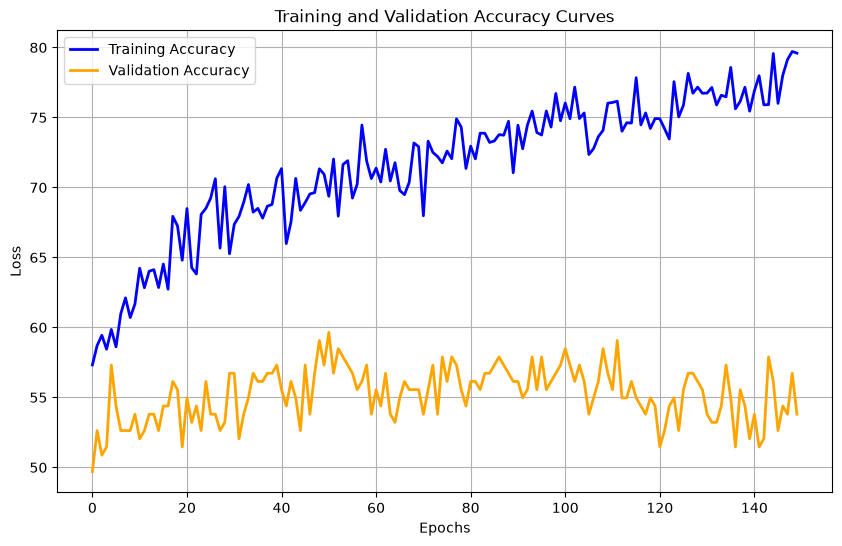

In [124]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(acc, label='Training Accuracy', color='blue', linewidth=2)
plt.plot(acc_val, label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Training and Validation Accuracy Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()